![]()


# **Getting Started**

Welcome to your first OpenCV Lesson. Here we'll learn to:
1. Import the OpenCV Model in Python
2. Load Images
3. Display Images
4. Save Images
5. Getting the Image Dimensions


In [1]:
# This is how we import OpenCV, we can't use OpenCV's functions without first doing this
import cv2

In [2]:
# Let's see what version we're running
print(cv2.__version__)

4.10.0


### **Dowloading Images**

If using Google Colab, we'll have to **upload our image**.

Colab is a Jupyther Notebook environment that runs on the **cloud** using Google's servers. As such, any file we wish to use needs to be uploaded to their servers.

In [3]:
# Download and unzip our images
!wget https://storage.googleapis.com/download.tensorflow.org/example_images/flower_photos.tgz
!tar -xzf flower_photos.tgz

--2026-10-17 11:11:26--  https://storage.googleapis.com/download.tensorflow.org/example_images/flower_photos.tgz
Resolving storage.googleapis.com (storage.googleapis.com)... 173.194.45.207, 142.251.179.207, 64.233.180.207, ...
Connecting to storage.googleapis.com (storage.googleapis.com)|173.194.45.207|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 228813984 (218M) [application/x-compressed-tar]
Saving to: ‘flower_photos.tgz.1’

flower_photos.tgz.1 100%[===================>] 218.21M   130MB/s    in 1.7s    

2026-10-17 11:11:28 (130 MB/s) - ‘flower_photos.tgz.1’ saved [228813984/228813984]



### **Loading Images**

In [4]:
# Load an image using 'imread' specifying the path to image
image = cv2.imread('./flower_photos/roses/10090824183_d02c613f10_m.jpg')

### **Displaying Images**

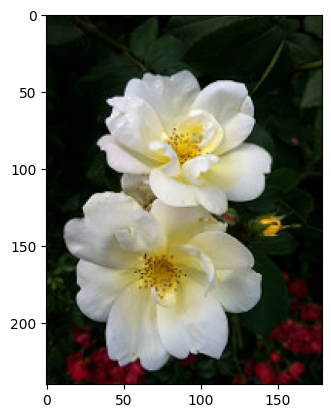

In [5]:
from matplotlib import pyplot as plt
from matplotlib.gridspec import GridSpec
import cv2

#Show the image with matplotlib
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.show()

Let's create a simple function to make displaying our images simpler and easier

In [6]:
def imshow(title = "", image = None):
    plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    plt.title(title)
    plt.show()

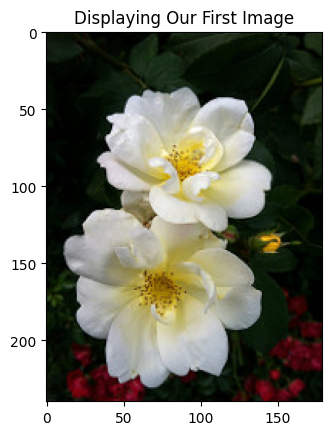

In [7]:
# Let's test it out
imshow("Displaying Our First Image", image)

### **Saving Images**

In [8]:
# Simply use 'imwrite' specificing the file name and the image to be saved
cv2.imwrite('output.jpg', image)

True

In [9]:
# Or save it as a PNG (Portable Network Graphics) which is a Lossless bitmap image format
cv2.imwrite('output.png', image)

True

### **Displaying Image Dimensions**

Remember Images are arrays:

![](https://raw.githubusercontent.com/rajeevratan84/ModernComputerVision/main/array.png?token=ADLZD2HNEL33JAKTYRM3B5C7WMIV4)



We need to use numpy to perform this operation. Don't worry, numpy will become one of your best friends if you're learning a Data Science and Computer Vision.

In [10]:
# Import numpy
import numpy as np

print(image.shape)

(240, 179, 3)


In [11]:
# To access a dimension, simply index it by using 0, 1 or 2.
image.shape[0]

240

In [12]:
print('Height of Image: {} pixels'.format(int(image.shape[0])))
print('Width of Image: {} pixels'.format(int(image.shape[1])))
print('Depth of Image: {} colors components'.format(int(image.shape[2])))

Height of Image: 240 pixels
Width of Image: 179 pixels
Depth of Image: 3 colors components


In [13]:
# Useful function to display omeges
def imshow(title = "", image = None, size = 10):

    # The line below is changed from w, h to h, w
    h, w = image.shape[0], image.shape[1]
    aspect_ratio = w/h

    plt.figure(figsize=(size * aspect_ratio, size))
    plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    plt.title(title)
    plt.show()

def add_title(img, text, font_size=2):
    h, w = img.shape[:2]
    title_bar = np.full((50, w, 3), 255, dtype=np.uint8)

    cv2.putText(
        title_bar,
        text,
        (10, 35),
        cv2.FONT_HERSHEY_SIMPLEX,
        1,
        (0, 0, 0),
        font_size,
        cv2.LINE_AA,
    )

    return np.vstack((title_bar, img))

def combile_images(imgs, figsize):
    combined = np.hstack(imgs)

    plt.figure(figsize=figsize)
    plt.imshow(cv2.cvtColor(combined, cv2.COLOR_BGR2RGB))
    plt.axis("off")
    plt.show()

def combine_images_diff_sizes(images, titles, figsize):
    # Use image widths as ratios
    width_ratios = [img.shape[1] for img in images]

    fig = plt.figure(figsize=figsize)
    gs = GridSpec(1, len(images), width_ratios=width_ratios)

    for i, (img, title) in enumerate(zip(images, titles)):
        ax = fig.add_subplot(gs[i])

        ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        ax.set_title(title)
        ax.axis("off")

    plt.tight_layout()
    plt.show()

### **Grayscaling Images**


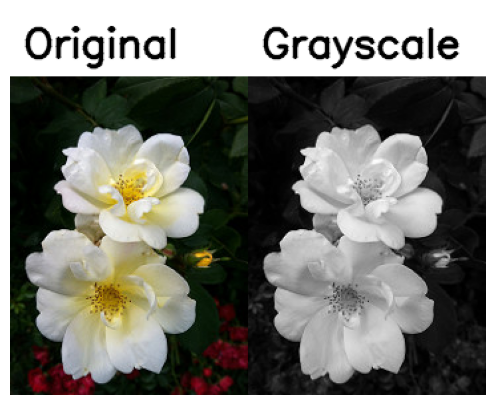

In [14]:
# We use cvtColor, to convert to grayscale
# It takes 2 arguments, the first being the input image
# The second being the color space conversion code
Gr = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

gray_image = cv2.merge([Gr, Gr, Gr])

# Add titles
imgs = [
    add_title(image.copy(), "Original"),
    add_title(gray_image.copy(), "Grayscale")
]

# Display side by side
combile_images(imgs, figsize=(12, 5))



# **Color Spaces**


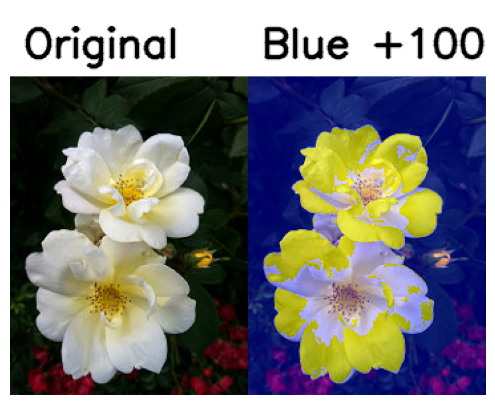

In [15]:
B, G, R = cv2.split(image)

# Original reconstruction
original = cv2.merge([B, G, R])

# Amplify blue channel
blue_boost = cv2.merge([
    B + 100,  # prevents uint8 overflow
    G,
    R
])

# Add titles
imgs = [
    add_title(original.copy(), "Original"),
    add_title(blue_boost.copy(), "Blue +100")
]

# Display side by side
combile_images(imgs, figsize=(12, 5))


## **The HSV Color Space**

![]()

- Hue: 0 - 179
- Saturation: 0 - 255
- Value (Intensity): 0 - 255

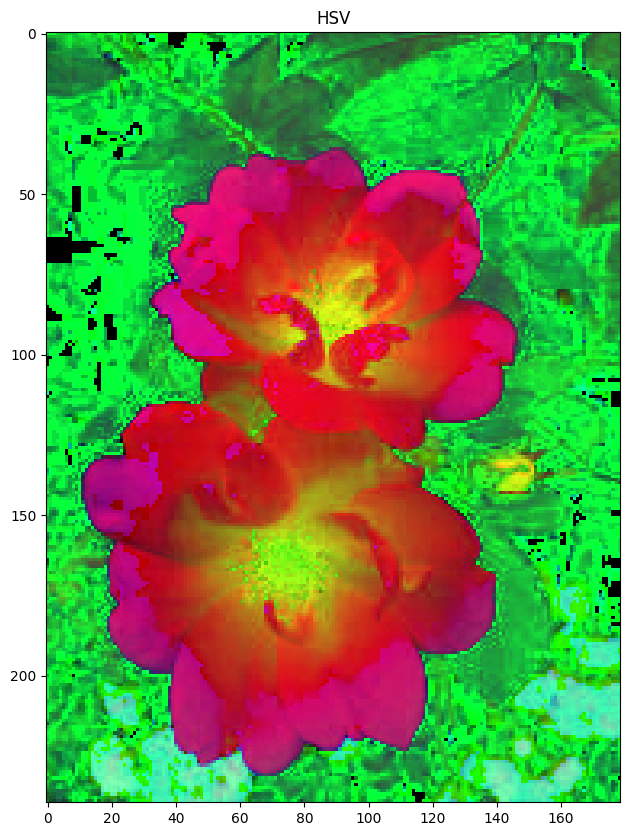

In [16]:
# Convert to HSV
hsv_image = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)
imshow('HSV', hsv_image)

#### This looks odd....why?

Because our plotting function was designed for RGB only images, not HSV

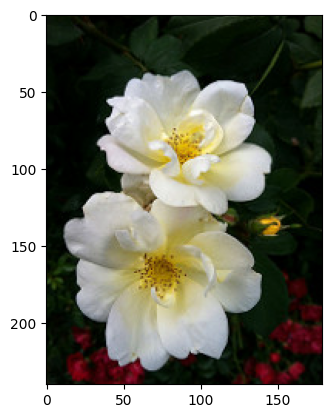

In [17]:
plt.imshow(cv2.cvtColor(hsv_image, cv2.COLOR_HSV2RGB))
plt.show()

### **Let's view each channel type in the HSV Color Space representation**

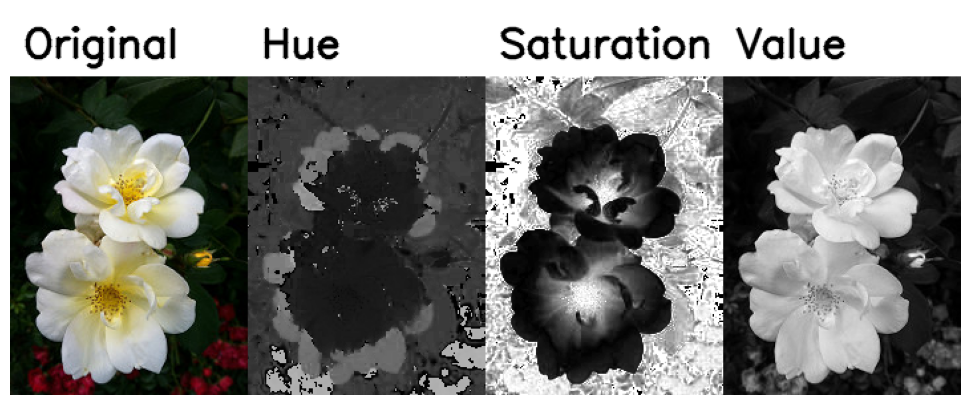

In [18]:
# Switching back to viewing the RGB representation
H = hsv_image[:, :, 0]
S= hsv_image[:, :, 1]
V= hsv_image[:, :, 2]

H_vis = cv2.cvtColor(H, cv2.COLOR_GRAY2BGR)
S_vis = cv2.cvtColor(S, cv2.COLOR_GRAY2BGR)
V_vis = cv2.cvtColor(V, cv2.COLOR_GRAY2BGR)

imgs = [
    add_title(image.copy(), "Original"),
    add_title(H_vis, "Hue"),
    add_title(S_vis, "Saturation"),
    add_title(V_vis, "Value")
]

combile_images(imgs, figsize=(18, 5))

## **Drawing images and shapes using OpenCV**


### **Drawing a line over our black square**

```cv2.line(image, starting cordinates, ending cordinates, color, thickness)```


### **Drawing Rectangles**

```cv2.rectangle(image, starting vertex, opposite vertex, color, thickness)```


### **Drawing some cirlcles**

```cv2.cirlce(image, center, radius, color, fill)```


### **Polygons**

```cv2.polylines(image, points, Closed?, color, thickness)```

if Closed = True, we join the first and last points.



**Note** cv2.polylines requires our data be shaped in this way:

pts shape is (4, 2) and pts_.shape needed for poly is (4, 1, 2)



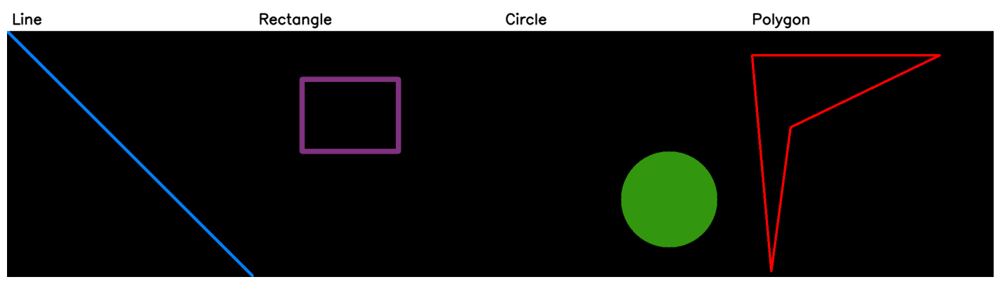

In [19]:
# Create a black image using numpy to create and array of black
img = np.zeros((512,512,3), np.uint8)

# Note this is an inplace operation, meaning it changes the input image
# Unlike many other OpenCV functions that return a new image leaving the input unaffected
# Remember our image was the black canvas
image_line = img.copy()
cv2.line(image_line, (0,0), (511,511), (255,127,0), 5)


image_rectangle = img.copy()
# Thickness - if positive. Negative thickness means that it is filled
cv2.rectangle(image_rectangle, (100,100), (300,250), (127,50,127), 10)

image_cirlce = img.copy()
cv2.circle(image_cirlce, (350, 350), 100, (15,150,50), -1)


image_polylines = img.copy()
# Let's define four points
pts = np.array( [[10,50], [400,50], [90,200], [50,500]], np.int32)

# Let's now reshape our points in form  required by polylines
pts_ = pts.reshape((-1,1,2))

cv2.polylines(image_polylines, [pts_], True, (0,0,255), 3)

print("\n\n**Note** cv2.polylines requires our data be shaped in this way:\n")
print(f"pts shape is {pts.shape} and pts_.shape needed for poly is {pts_.shape}\n")



# Add titles
imgs = [
    add_title(image_line.copy(), "Line"),
    add_title(image_rectangle.copy(), "Rectangle"),
    add_title(image_cirlce.copy(), "Circle"),
    add_title(image_polylines.copy(), "Polygon")
]

# Combine into one row
combile_images(imgs, figsize=(20, 5))

### **And now for adding text with cv2.putText**

```cv2.putText(image, 'Text to Display', bottom left starting point, Font, Font Size, Color, Thickness)```

**Available Fonts**
- FONT_HERSHEY_SIMPLEX, FONT_HERSHEY_PLAIN
- FONT_HERSHEY_DUPLEX,FONT_HERSHEY_COMPLEX
- FONT_HERSHEY_TRIPLEX, FONT_HERSHEY_COMPLEX_SMALL
- FONT_HERSHEY_SCRIPT_SIMPLEX
- FONT_HERSHEY_SCRIPT_COMPLEX

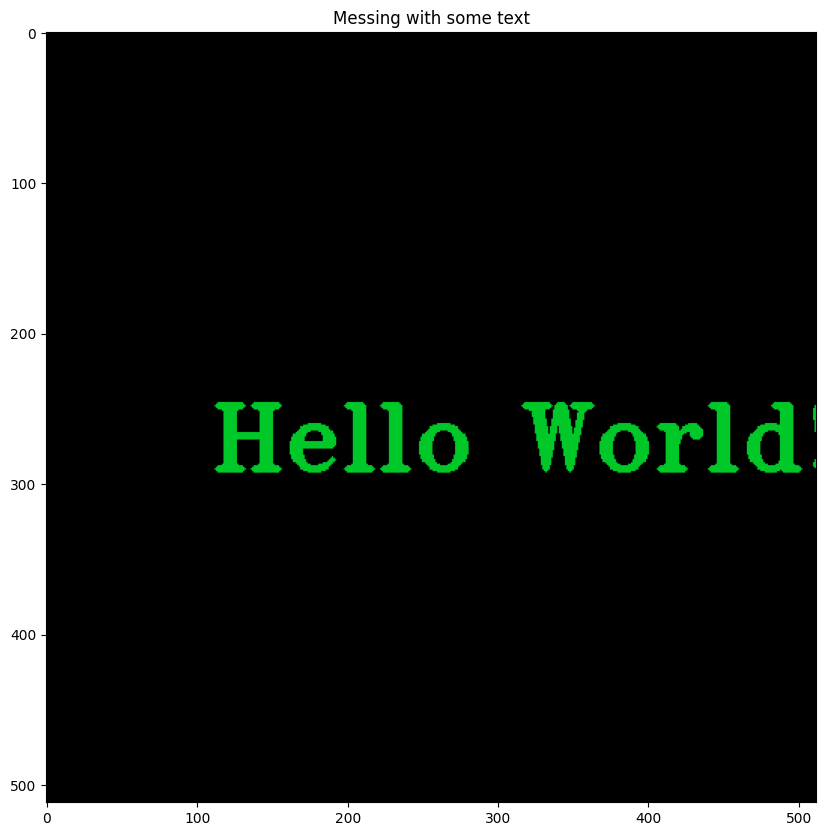

In [20]:
image_text = img.copy()
ourString =  'Hello World!'
cv2.putText(image_text, ourString, (110,290), cv2.FONT_HERSHEY_TRIPLEX, 2, (40,200,0), 4)
imshow("Messing with some text", image_text)

### **Translations**

This an affine transform that simply shifts the position of an image. (left or right).

We use cv2.warpAffine to implement these transformations.

```cv2.warpAffine(image, T, (width, height))```


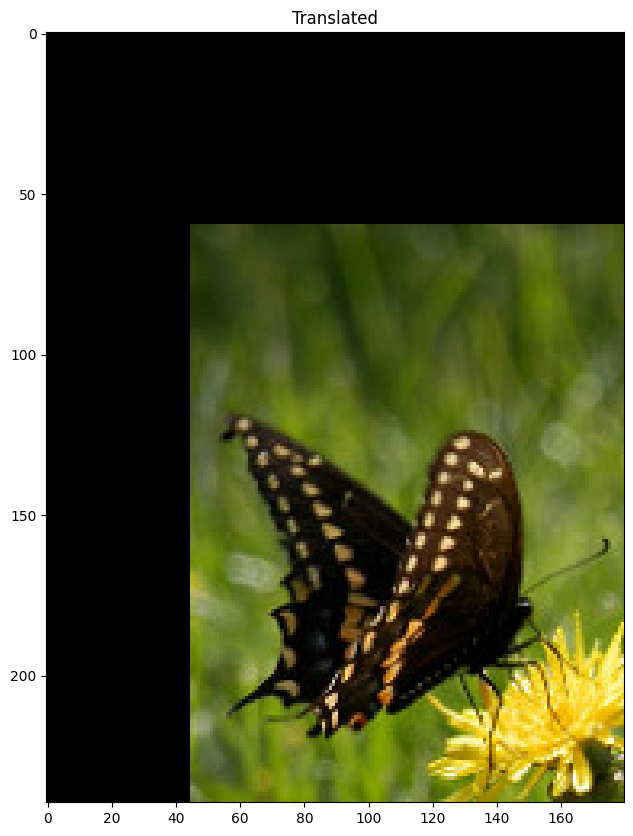

In [21]:
image = cv2.imread('./flower_photos/dandelion/10477378514_9ffbcec4cf_m.jpg')
# Store height and width of the image
height, width = image.shape[:2]

# We shift it by quarter of the height and width
quarter_height, quarter_width = height/4, width/4

# Our Translation
#       | 1 0 Tx |
#  T  = | 0 1 Ty |

# T is our translation matrix
T = np.float32([[1, 0, quarter_width], [0, 1,quarter_height]])

# We use warpAffine to transform the image using the matrix, T
img_translation = cv2.warpAffine(image, T, (width, height))
imshow("Translated", img_translation)

### **Rotations**

```cv2.getRotationMatrix2D(rotation_center_x, rotation_center_y, angle of rotation, scale)```

![]()

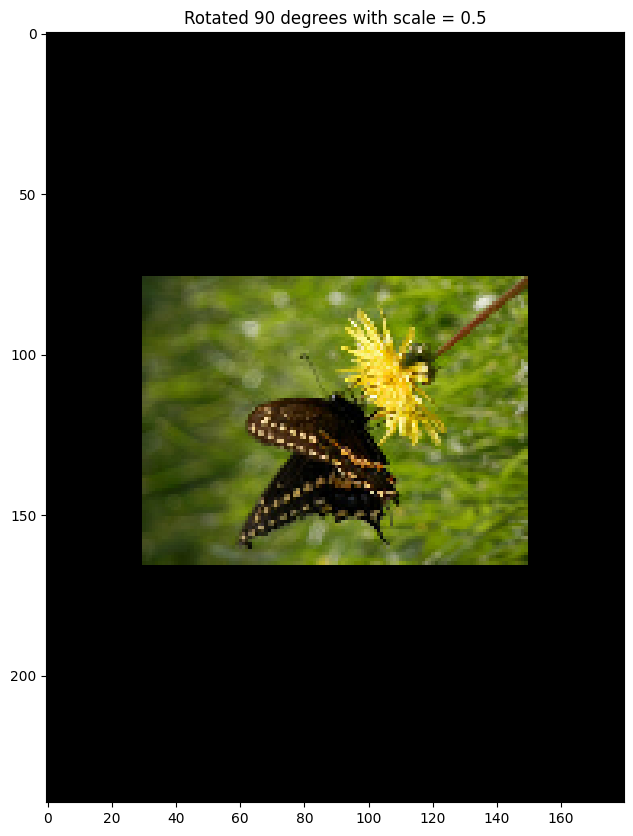

In [22]:
# Divide by two to rototate the image around its centre
rotation_matrix = cv2.getRotationMatrix2D((width/2, height/2), 90, 0.5)

# Input our image, the rotation matrix and our desired final width and height
rotated_image = cv2.warpAffine(image, rotation_matrix, (width, height))
imshow("Rotated 90 degrees with scale = 0.5", rotated_image)

Notice all the black space surrounding the image.

We could now crop the image as we can calculate it's new size (we haven't learned cropping yet!).

### **Rotations with cv2.transpose** (less flexible)

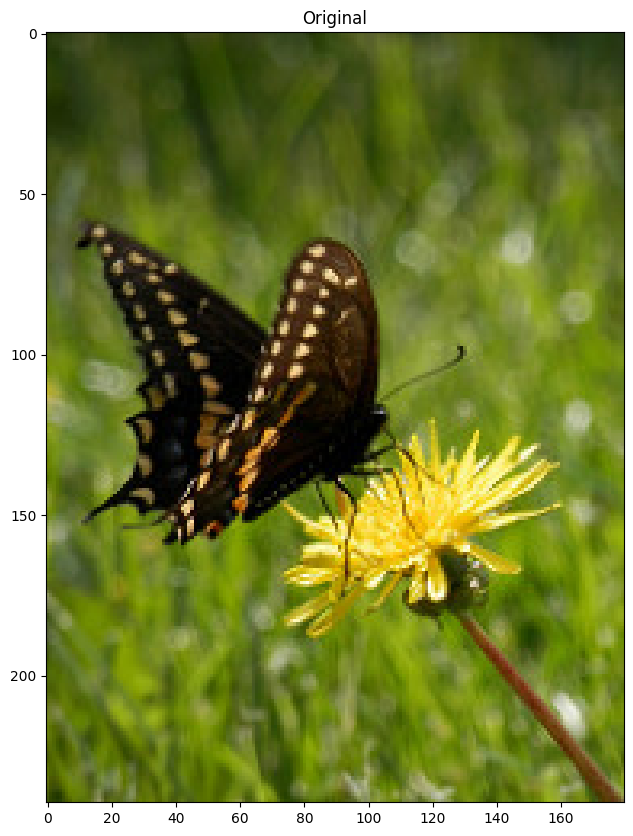

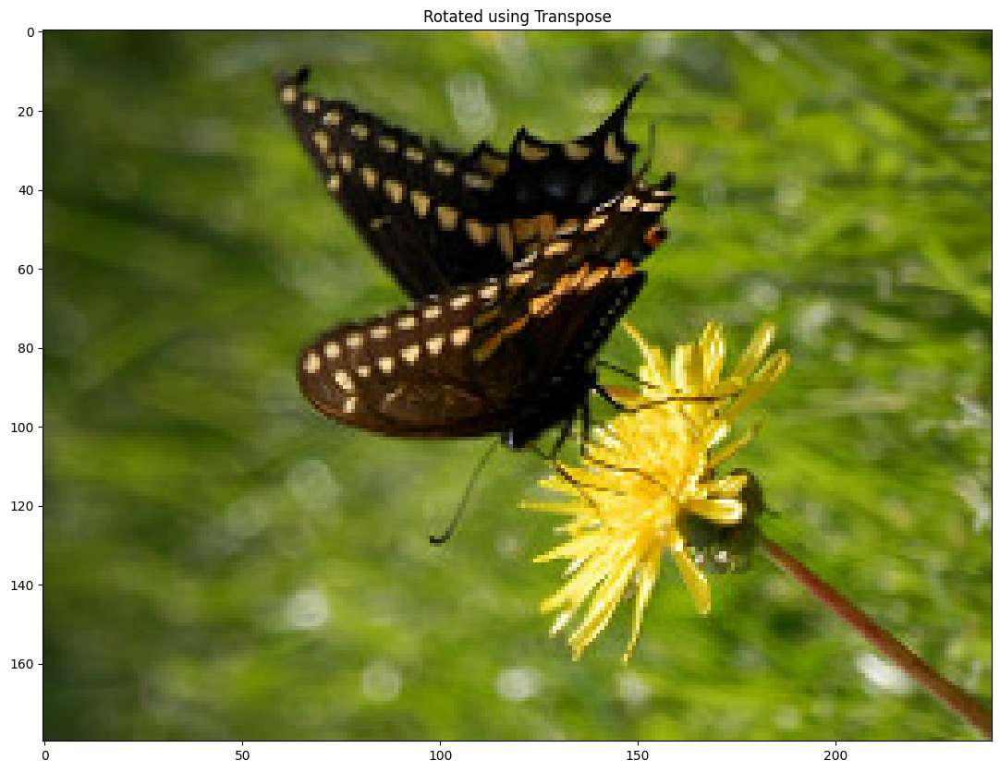

In [23]:
rotated_image = cv2.transpose(image)
imshow("Original", image)
imshow("Rotated using Transpose", rotated_image)

# **Scaling, Re-sizing, Interpolations and Cropping**

Re-sizing is a simple function that we execute using the cv2.resize function, it's arguments are:

```cv2.resize(image, dsize(output image size), x scale, y scale, interpolation)```
- if dsize is None the output image is calculated as a function of scaling using x & y scale

#### **List of Interpolation Methods:**
- cv2.INTER_AREA - Good for shrinking or down sampling
- cv2.INTER_NEAREST - Fastest
- cv2.INTER_LINEAR - Good for zooming or up sampling (default)
- cv2.INTER_CUBIC - Better
- cv2.INTER_LANCZOS4 - Best



### **Types of re-scaling Methods in OpenCV**

- **INTER_NEAREST** – a nearest-neighbor interpolation
- **INTER_LINEAR** – a bilinear interpolation (used by default)
- **INTER_AREA** – resampling using pixel area relation. It may be a preferred method for image decimation, as it gives moire’-free results. But when the image is zoomed, it is similar to theINTER_NEAREST method.
- **INTER_CUBIC** – a bicubic interpolation over 4×4 pixel neighborhood
- **INTER_LANCZOS4** – a Lanczos interpolation over 8×8 pixel neighborhood

(180, 135)


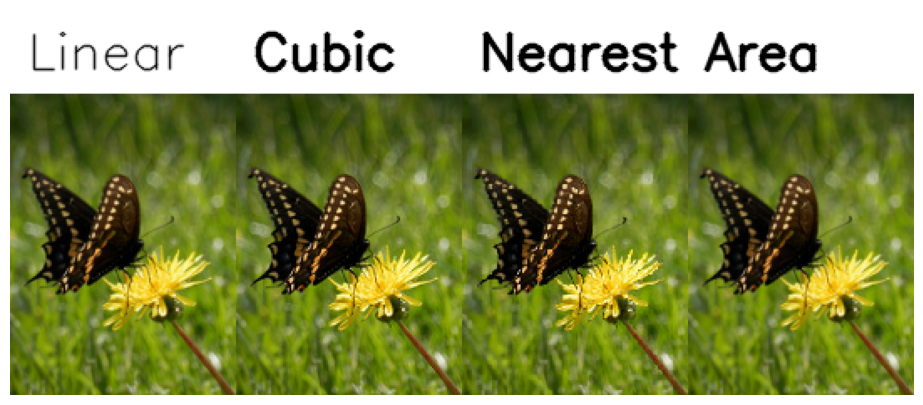

In [24]:
# If no interpolation is specified cv.INTER_LINEAR is used as default
# Let's make our image 3/4 of it's original size
image_scaled = cv2.resize(image, None, fx=0.75, fy=0.75)

# Let's double the size of our image
img_scaled2 = cv2.resize(image, None, fx=0.75, fy=0.75, interpolation = cv2.INTER_CUBIC)

# Let's double the size of our image using inter_nearest interpolation
img_scaled3 = cv2.resize(image, None, fx=0.75, fy=0.75, interpolation = cv2.INTER_NEAREST)

# Let's skew the re-sizing by setting exact dimensions
print(img_scaled3.shape[0:2])
img_scaled4 = cv2.resize(image, img_scaled3.shape[0:2][::-1], interpolation = cv2.INTER_AREA)

# Add titles
imgs = [
    add_title(image_scaled.copy(), "Linear",font_size=1),
    add_title(img_scaled2.copy(), "Cubic"),
    add_title(img_scaled3.copy(), "Nearest"),
    add_title(img_scaled4.copy(), "Area")
]

# Combine into one row
combile_images(imgs, figsize=(20, 5))

#### Interpolation Speed comparition

In [25]:
import matplotlib.pyplot as plt
import time

methods = {
    "NEAREST": cv2.INTER_NEAREST,
    "LINEAR": cv2.INTER_LINEAR,
    "CUBIC": cv2.INTER_CUBIC,
    "LANCZOS4": cv2.INTER_LANCZOS4
}

N = 1000

for name, interp in methods.items():

    start = time.perf_counter()

    for _ in range(N):
        cv2.resize(img, (135,180), interpolation=interp)

    elapsed = time.perf_counter() - start

    print(f"{name:10s}: {elapsed/N*1000:.4f} ms")

NEAREST   : 0.1247 ms
LINEAR    : 0.2474 ms
CUBIC     : 0.6852 ms
LANCZOS4  : 2.5234 ms


#### interpolation Quality comparition
Interpreting the results

PSNR





*   40 dB: excellent
*   30-40 dB: good
*   20-30 dB: noticeable degradation


SSIM

*   1.0 = identical
*   0.95 = very high quality
*   0.8-0.95 = acceptable
*   < 0.8 = visible distortions

In [26]:
from skimage.metrics import peak_signal_noise_ratio, structural_similarity

methods = {
    "NEAREST": cv2.INTER_NEAREST,
    "LINEAR": cv2.INTER_LINEAR,
    "CUBIC": cv2.INTER_CUBIC,
    "LANCZOS4": cv2.INTER_LANCZOS4
}

for name, method in methods.items():

    small = cv2.resize(image.copy(), (135, 180), interpolation=method)

    restored = cv2.resize(
        small,
        (image.shape[1], image.shape[0]),
        interpolation=method
    )

    psnr = peak_signal_noise_ratio(image, restored)

    ssim = structural_similarity(
        image,
        restored,
        channel_axis=2
    )

    print(
        f"{name:10s} | "
        f"PSNR={psnr:.2f} dB | "
        f"SSIM={ssim:.4f}"
    )

NEAREST    | PSNR=22.46 dB | SSIM=0.7777
LINEAR     | PSNR=30.59 dB | SSIM=0.9560
CUBIC      | PSNR=33.99 dB | SSIM=0.9809
LANCZOS4   | PSNR=34.43 dB | SSIM=0.9816


## **Image Pyraminds**

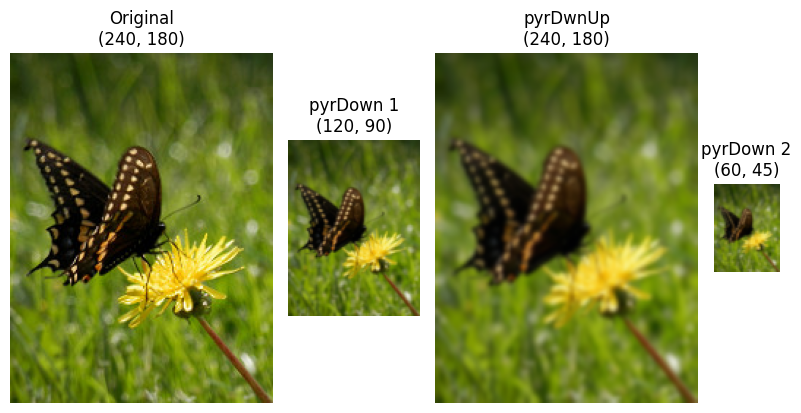

In [27]:
import cv2
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec

smaller = cv2.pyrDown(image.copy())
larger = cv2.pyrUp(smaller)
even_smaller = cv2.pyrDown(smaller)

images = [image, smaller, larger, even_smaller]

titles = [
    f"Original\n{image.shape[:2]}",
    f"pyrDown 1\n{smaller.shape[:2]}",
    f"pyrDwnUp\n{larger.shape[:2]}",
    f"pyrDown 2\n{even_smaller.shape[:2]}"
]

combine_images_diff_sizes(images, titles, figsize=(8, 4))


# **Cropping**

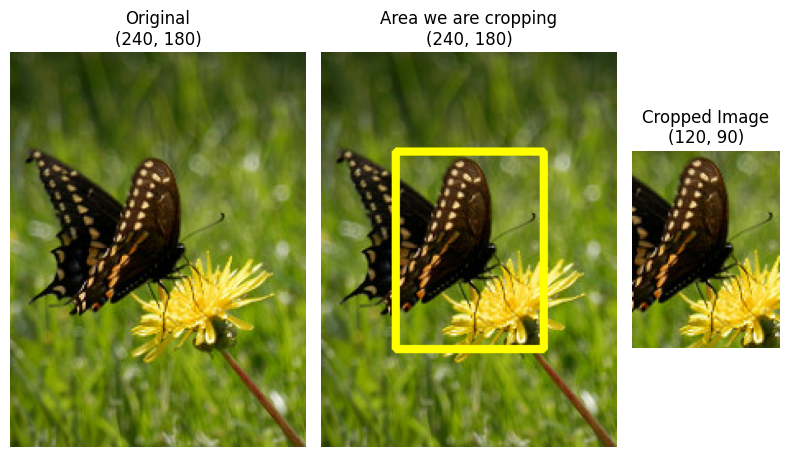

In [28]:
# Get our image dimensions
height, width = image.shape[:2]

# Let's get the starting pixel coordiantes (top  left of cropping rectangle)
# using 0.25 to get the x,y position that is 1/4 down from the top left (0,0)
start_row, start_col = int(height * .25), int(width * .25)

# Let's get the ending pixel coordinates (bottom right)
end_row, end_col = int(height * .75), int(width * .75)

# Simply use indexing to crop out the rectangle we desire
cropped = image[start_row:end_row , start_col:end_col]

# The cv2.rectangle function draws a rectangle over our image (in-place operation)
copy = image.copy()
cv2.rectangle(copy, (start_col,start_row), (end_col,end_row), (0,255,255), 3)


images = [image, copy, cropped]

titles = [
    f"Original\n{image.shape[:2]}",
    f"Area we are cropping\n{copy.shape[:2]}",
    f"Cropped Image\n{cropped.shape[:2]}",
]

combine_images_diff_sizes(images, titles, figsize=(8, 5))

## **Bitwise Operations and Masking**

To demonstrate these operations let's create some simple images

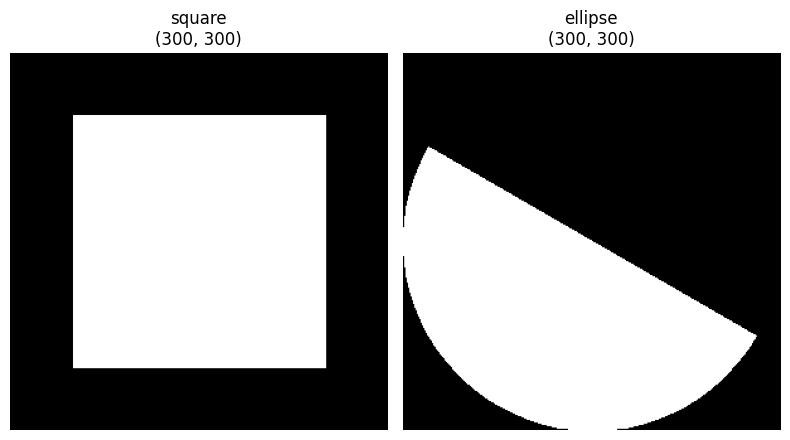

In [29]:
# If you're wondering why only two dimensions, well this is a grayscale image,

# Making a square
square = np.zeros((300, 300), np.uint8)
cv2.rectangle(square, (50, 50), (250, 250), 255, -2)

# Making a ellipse
ellipse = np.zeros((300, 300), np.uint8)
cv2.ellipse(ellipse, (150, 150), (150, 150), 30, 0, 180, 255, -1)

images = [square, ellipse]
titles = [
    f"square\n{square.shape}",
    f"ellipse\n{ellipse.shape}"
]

combine_images_diff_sizes(images, titles, (8,5))

### **Experimenting with some bitwise operations such as AND, OR, XOR and NOT**

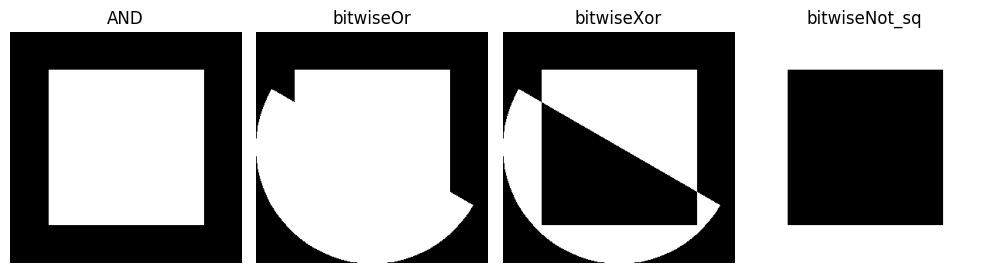

In [30]:
# Shows only where they intersect
And = cv2.bitwise_and(square, ellipse)

# Shows where either square or ellipse is
bitwiseOr = cv2.bitwise_or(square, ellipse)

# Shows where either exist by itself
bitwiseXor = cv2.bitwise_xor(square, ellipse)

# Shows everything that isn't part of the square
bitwiseNot_sq = cv2.bitwise_not(square)

images = [square, bitwiseOr, bitwiseXor, bitwiseNot_sq]
titles = [
    f"AND",
    f"bitwiseOr",
    f"bitwiseXor",
    f"bitwiseNot_sq",
]

combine_images_diff_sizes(images, titles, (10, 5))

# Notice the last operation inverts the image totally

# **Convolutions, Blurring and Sharpening Images**

1. Convolution Operations
2. Blurring
3. Denoising
4. Sharpening

### **Blurring using Convolutions**

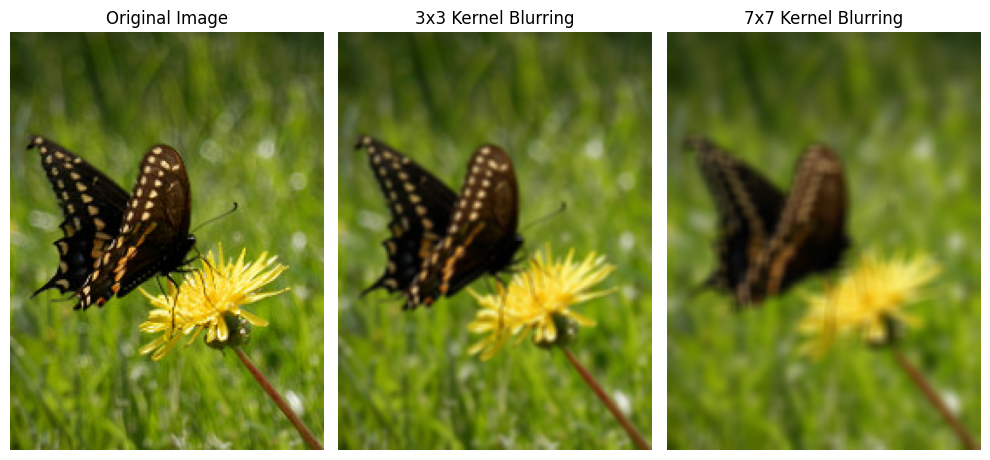

In [31]:
# Creating our 3 x 3 kernel
kernel_3x3 = np.ones((3, 3), np.float32) / 9

# We use the cv2.fitler2D to conovlve the kernal with an image
blurred = cv2.filter2D(image, -1, kernel_3x3)

# Creating our 7 x 7 kernel
kernel_7x7 = np.ones((7, 7), np.float32) / 49

blurred2 = cv2.filter2D(image, -1, kernel_7x7)


images = [image, blurred, blurred2]
titles = [
    f"Original Image",
    f"3x3 Kernel Blurring",
    f"7x7 Kernel Blurring",
]

combine_images_diff_sizes(images, titles, (10, 5))


### **Other commonly used blurring methods in OpenCV**
- Regular Blurring
- Gaussian Blurring
- Median Blurring

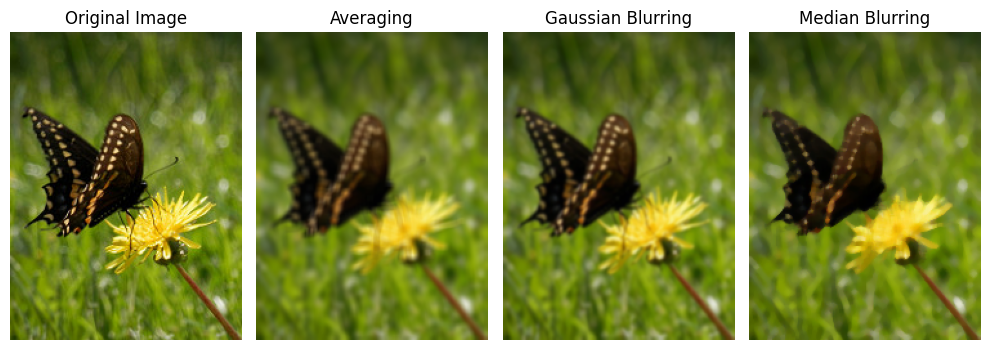

In [32]:
# Averaging done by convolving the image with a normalized box filter.
# This takes the pixels under the box and replaces the central element
# Box size needs to odd and positive
blur = cv2.blur(image, (5,5))

# Instead of box filter, gaussian kernel
Gaussian = cv2.GaussianBlur(image, (5,5), 0)

# Takes median of all the pixels under kernel area and central
# element is replaced with this median value
median = cv2.medianBlur(image, 5)

images = [image, blur, Gaussian, median]
titles = [
    f"Original Image",
    f"Averaging",
    f"Gaussian Blurring",
    f"Median Blurring",
]

combine_images_diff_sizes(images, titles, (10, 5))

### **Bilateral Filter**

Bilateral is very effective in noise removal while keeping edges sharp

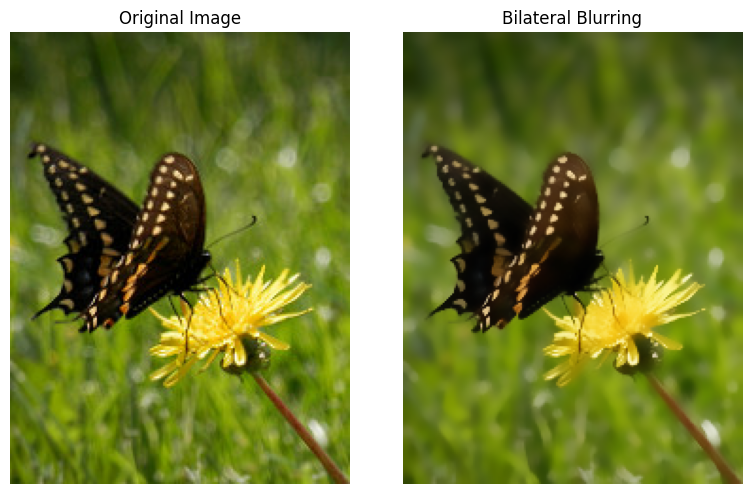

In [33]:
bilateral = cv2.bilateralFilter(image, 9, 75, 75)

images = [image, bilateral]
titles = [
    f"Original Image",
    f"Bilateral Blurring"
]

combine_images_diff_sizes(images, titles, (8, 5))

## **Image De-noising - Non-Local Means Denoising**

**There are 4 variations of Non-Local Means Denoising:**

- cv2.fastNlMeansDenoising() - works with a single grayscale images
- cv2.fastNlMeansDenoisingColored() - works with a color image.
- cv2.fastNlMeansDenoisingMulti() - works with image sequence captured in short period of time (grayscale images)
- cv2.fastNlMeansDenoisingColoredMulti() - same as above, but for color images.

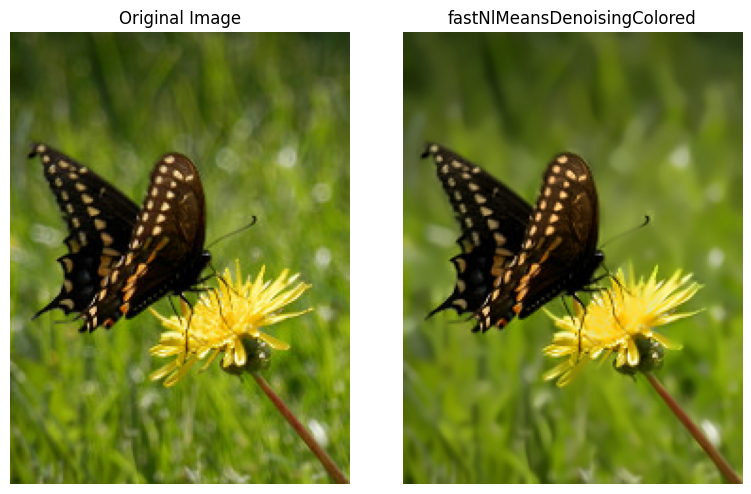

In [34]:

dst = cv2.fastNlMeansDenoisingColored(image, None, 6, 6, 7, 21)



images = [image, dst]
titles = [
    f"Original Image",
    f"fastNlMeansDenoisingColored"
]

combine_images_diff_sizes(images, titles, (8, 5))



### **Sharpening Images**

1. Standard Sharpen Kernel

2. Mild Sharpen Kernel

3. Unsharp Masking (Most Common)

4. Laplacian Sharpening

5. High-Pass Filter Sharpening

6. Bilateral + Sharpen




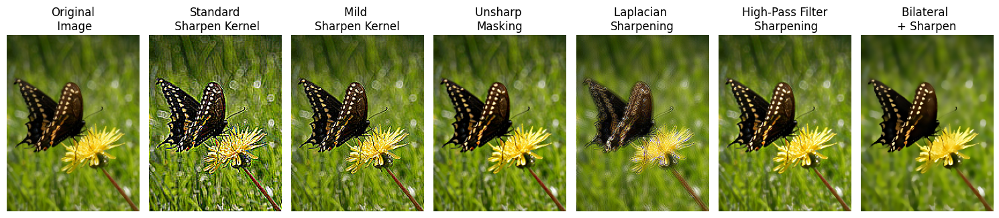

In [35]:
#1. Standard Sharpen Kernel
# Create our shapening kernel, remember it must sum to one
kernel_sharpening = np.array([[-1,-1,-1],
                              [-1, 9,-1],
                              [-1,-1,-1]])

# applying the sharpening kernel to the image
sharpened = cv2.filter2D(image, -1, kernel_sharpening)

#2. Mild Sharpen Kernel
kernel_sharpening2 = np.array([[0,-1,0],
                              [-1, 5,-1],
                              [0,-1,0]])

sharpened2 = cv2.filter2D(image, -1, kernel_sharpening2)

#3. Unsharp Masking (Most Common)
blurred = cv2.GaussianBlur(image, (0,0), 3)

sharp3 = cv2.addWeighted(
    image, 1.5,
    blurred, -0.5,
    0
)

#4. Laplacian Sharpening
lap = cv2.Laplacian(image, cv2.CV_64F)

sharp4 = cv2.convertScaleAbs(
    image.astype(np.float64) + lap
)

#5. High-Pass Filter Sharpening
blur = cv2.GaussianBlur(image, (11,11), 0)

highpass = cv2.subtract(image, blur)

sharp5 = cv2.add(image, highpass)

#6. Bilateral + Sharpen
denoised = cv2.bilateralFilter(image, 9, 75, 75)

sharp6 = cv2.addWeighted(
    denoised, 1.5,
    cv2.GaussianBlur(denoised,(0,0),3), -0.5, 0
)

images = [image, sharpened, sharpened2, sharp3, sharp4, sharp5, sharp6]

titles = [
    f"Original\n Image",
    f"Standard\n Sharpen Kernel",
    f"Mild \nSharpen Kernel",
    f"Unsharp \nMasking",
    f"Laplacian \nSharpening",
    f"High-Pass Filter\n Sharpening",
    f"Bilateral \n+ Sharpen"
]

combine_images_diff_sizes(images, titles, (15, 5))


# **Thresholding, Binarization & Adaptive Thresholding**

1. Binarized Images
2. Thresholding Methods
3. Adaptive Thresholding
4. SkImage's Threshold Local

In [36]:
!wget https://raw.githubusercontent.com/opencv/opencv/master/samples/data/sudoku.png
img = cv2.imread('sudoku.png', cv2.IMREAD_GRAYSCALE)

--2026-10-17 11:11:55--  https://raw.githubusercontent.com/opencv/opencv/master/samples/data/sudoku.png
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 250720 (245K) [image/png]
Saving to: ‘sudoku.png.1’

sudoku.png.1        100%[===================>] 244.84K  --.-KB/s    in 0.004s  

2026-10-17 11:11:55 (56.7 MB/s) - ‘sudoku.png.1’ saved [250720/250720]



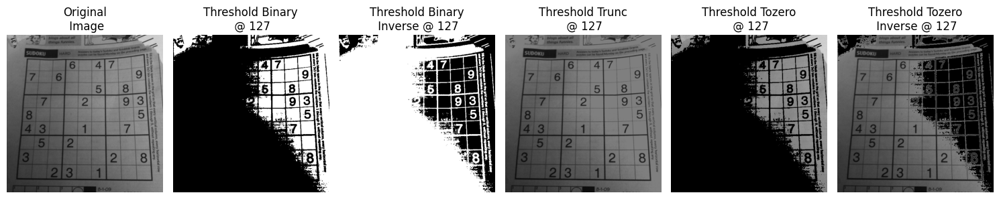

In [37]:

# Values below 127 goes to 0 or black, everything above goes to 255 (white)
ret,thresh1 = cv2.threshold(img, 127, 255, cv2.THRESH_BINARY)

# Values below 127 go to 255 and values above 127 go to 0 (reverse of above)
ret,thresh2 = cv2.threshold(img, 127, 255, cv2.THRESH_BINARY_INV)

# Values above 127 are truncated (held) at 127 (the 255 argument is unused)
ret,thresh3 = cv2.threshold(img, 127, 255, cv2.THRESH_TRUNC)

# Values below 127 go to 0, above 127 are unchanged
ret,thresh4 = cv2.threshold(img, 127, 255, cv2.THRESH_TOZERO)

# Reverse of the above, below 127 is unchanged, above 127 goes to 0
ret,thresh5 = cv2.threshold(img, 127, 255, cv2.THRESH_TOZERO_INV)

images = [img, thresh1, thresh2, thresh3, thresh4, thresh5]
titles = [
    f"Original\n Image",
    f"Threshold Binary\n @ 127",
    f"Threshold Binary\n Inverse @ 127",
    f"Threshold Trunc\n @ 127",
    f"Threshold Tozero\n @ 127",
    f"Threshold Tozero\n Inverse @ 127"
]

combine_images_diff_sizes(images, titles, (15, 5))

#### **Adaptive Thresholding**

1. ADAPTIVE_THRESH_MEAN_C
2. THRESH_OTSU


**Blurring** is a crucial preprocessing step before thresholding because it **removes high-frequency noise** and **smooths image gradients**

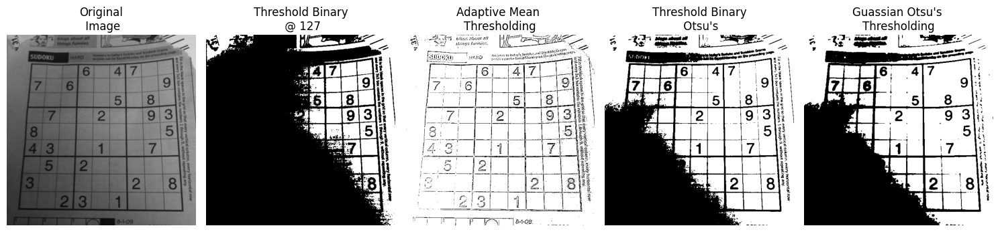

In [38]:
# Values below 127 goes to 0 (black, everything above goes to 255 (white)
ret,thresh1 = cv2.threshold(img, 127, 255, cv2.THRESH_BINARY)

# It's good practice to blur images as it removes noise
#img = cv2.GaussianBlur(img, (3, 3), 0)

# Using adaptiveThreshold
thresh = cv2.adaptiveThreshold(img, 255, cv2.ADAPTIVE_THRESH_MEAN_C, cv2.THRESH_BINARY, 3, 5)

_, th2 = cv2.threshold(img, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

# Otsu's thresholding after Gaussian filtering
blur = cv2.GaussianBlur(img, (5,5), 0)
_, th3 = cv2.threshold(blur, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

images = [img, thresh1, thresh, th2, th3]
titles = [
    f"Original\n Image",
    f"Threshold Binary\n @ 127",
    f"Adaptive Mean \nThresholding",
    f"Threshold Binary\n Otsu's",
    f"Guassian Otsu's \nThresholding"
]

combine_images_diff_sizes(images, titles, (15, 5))

### **SkImage Threshold Local**


``threshold_local(image, block_size, offset=10)``

The threshold_local function, calculates thresholds in regions with a characteristic size ``block_size`` surrounding each pixel (i.e. local neighborhoods). Each threshold value is the weighted mean of the local neighborhood minus an ``offset`` value

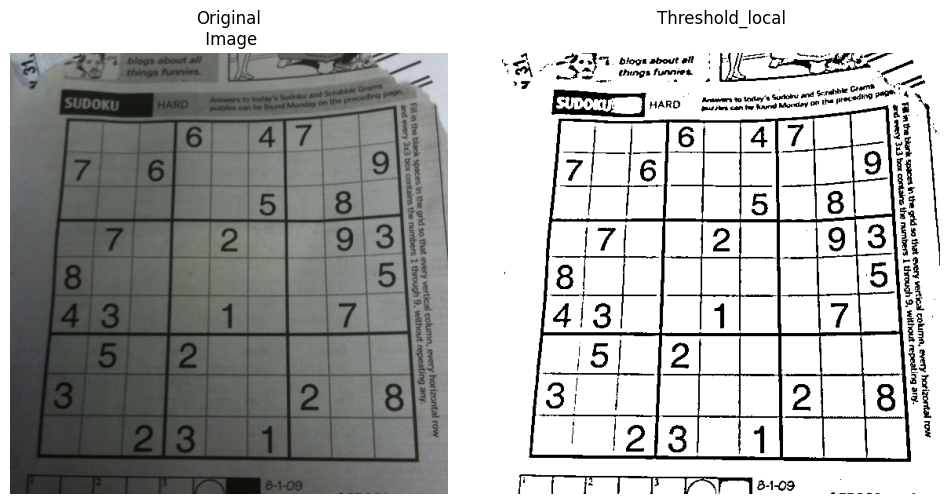

In [39]:
from skimage.filters import threshold_local

img = cv2.imread('sudoku.png')

# We get the "Value component" from the HSV color space
# then we apply adaptive thresholdingto
V = cv2.split(cv2.cvtColor(img, cv2.COLOR_BGR2HSV))[2]
T = threshold_local(V, 25, offset=10, method="gaussian")

# Apply the threshold operation
thresh = (V > T).astype("uint8") * 255

images = [img, thresh]
titles = [
    f"Original\n Image",
    f"Threshold_local\n"
]

combine_images_diff_sizes(images, titles, (10, 5))

# **Dilation, Erosion and Edge Detection**

1. Dilation
2. Erosion
3. Opening
4. Closing
5. Canny Edge Detection

In [40]:
!wget https://raw.githubusercontent.com/opencv/opencv/master/samples/data/smarties.png


--2026-10-17 11:11:56--  https://raw.githubusercontent.com/opencv/opencv/master/samples/data/smarties.png
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 90815 (89K) [image/png]
Saving to: ‘smarties.png.1’

smarties.png.1      100%[===================>]  88.69K  --.-KB/s    in 0.003s  

2026-10-17 11:11:56 (28.8 MB/s) - ‘smarties.png.1’ saved [90815/90815]



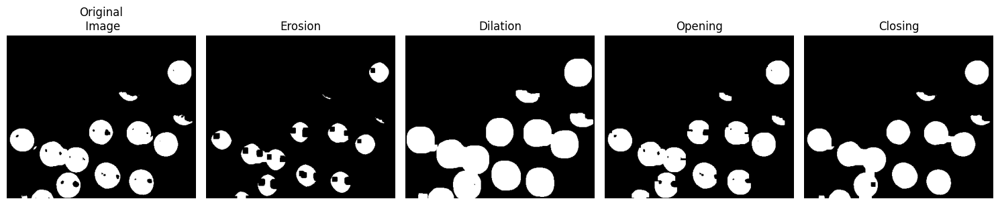

In [41]:
gray_img = cv2.imread('smarties.png', 0)

_, img_th = cv2.threshold(gray_img, 150, 255, cv2.THRESH_BINARY_INV)


# Let's define our kernel size
kernel = np.ones((5,5), np.uint8)

# Now we erode
erosion = cv2.erode(img_th, kernel, iterations = 2)

# Dilate here
dilation = cv2.dilate(img_th, kernel, iterations = 2)

# Opening - Good for removing noise
opening = cv2.morphologyEx(img_th, cv2.MORPH_OPEN, kernel, iterations=2)

# Closing - Good for removing noise
closing = cv2.morphologyEx(img_th, cv2.MORPH_CLOSE, kernel, iterations=2)

images = [img_th, erosion, dilation, opening, closing]
titles = [
    f"Original\n Image",
    f"Erosion",
    f"Dilation",
    f"Opening",
    f"Closing"
]

combine_images_diff_sizes(images, titles, (15,5))

## **Canny Edge Detection**

Edge detection needs a threshold to tell what difference/change should be counted as edge.


We need to provide two values: **threshold1** and **threshold2**.


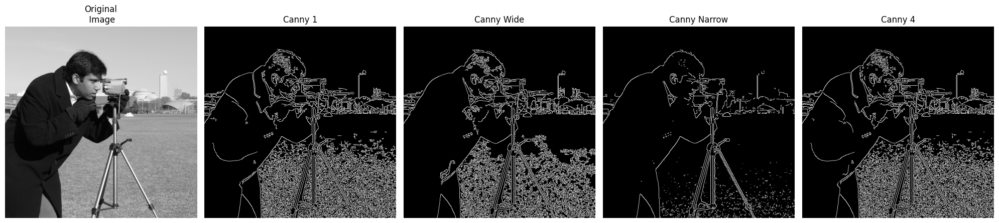

In [42]:
from skimage import data

img = data.camera()

# Canny Edge Detection uses gradient values as thresholds
# The first threshold gradient
canny1 = cv2.Canny(img, 50, 120)

# Wide edge thresholds expect lots of edges
canny2 = cv2.Canny(img, 10, 200)

# Narrow threshold, expect less edges
canny3 = cv2.Canny(img, 200, 240)

canny4 = cv2.Canny(img, 60, 110)

images = [img, canny1, canny2, canny3, canny4]
titles = [
    f"Original\n Image",
    f"Canny 1",
    f"Canny Wide",
    f"Canny Narrow",
    f"Canny 4"
]

combine_images_diff_sizes(images, titles, (20, 5))

#### **Auto Canny**

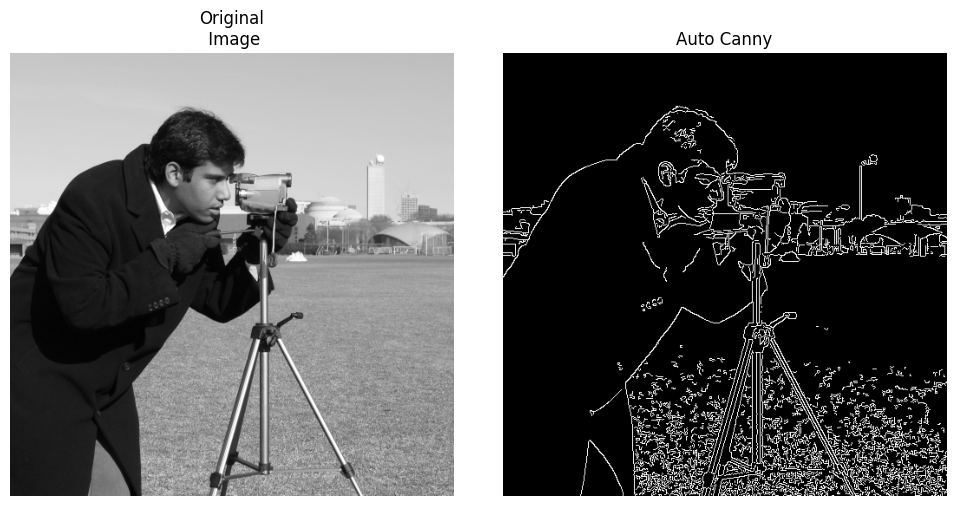

In [43]:
def autoCanny(image):
  # Finds optimal thresholds based on median image pixel intensity
  blurred_img = cv2.blur(image, ksize=(5,5))
  med_val = np.median(image)
  lower = int(max(0, 0.66 * med_val))
  upper = int(min(255, 1.33 * med_val))
  edges = cv2.Canny(image=image, threshold1=lower, threshold2=upper)
  return edges

auto_canny = autoCanny(img)

images = [img, auto_canny]
titles = [
    f"Original\n Image",
    f"Auto Canny"
]

combine_images_diff_sizes(images, titles, (10,5))

# **Contours**

1. Using findContours
2. Drawing Contours
3. Hierachy of Contours
4. Contouring Modes (Simple vs Approx)

findContours()      -> Detect boundaries

drawContours()      -> Visualize contours

RETR_EXTERNAL       -> Outer contours only

RETR_LIST           -> All contours, no hierarchy

RETR_TREE           -> Full hierarchy

CHAIN_APPROX_NONE   -> Keep all points

CHAIN_APPROX_SIMPLE -> Compress straight lines


Most common combination:


contours, hierarchy = cv2.findContours(

    thresh,
    cv2.RETR_EXTERNAL,
    cv2.CHAIN_APPROX_SIMPLE

)


Number of contours: 28
Hierarchy shape: (1, 28, 4)


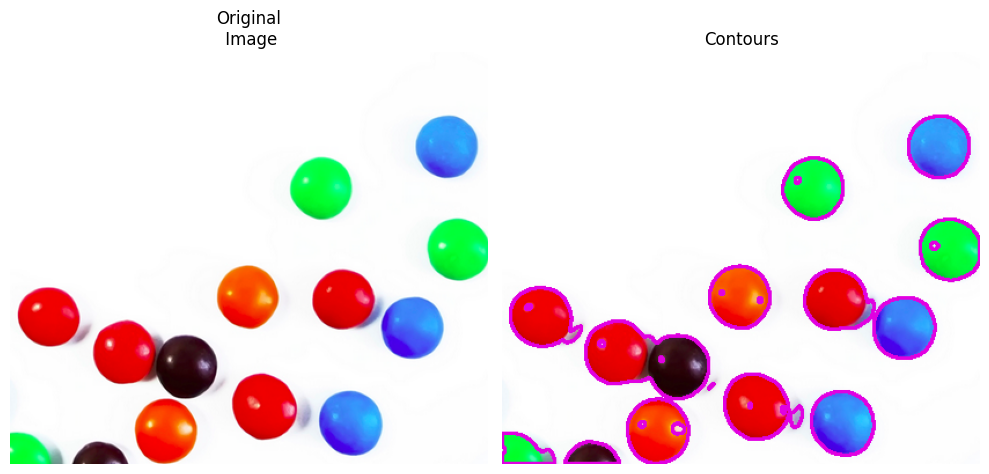

In [44]:
img_color = cv2.imread('smarties.png')
gray = cv2.cvtColor(img_color, cv2.COLOR_BGR2GRAY)

# Threshold
_, thresh = cv2.threshold(gray, 200, 255, cv2.THRESH_BINARY_INV)

# Find contours
contours, hierarchy = cv2.findContours(
    thresh,
    cv2.RETR_TREE,
    cv2.CHAIN_APPROX_SIMPLE
)

print("Number of contours:", len(contours))
print("Hierarchy shape:", hierarchy.shape)

# Draw all contours
result = img_color.copy()
cv2.drawContours(result, contours, -1, (225,0,225), 2)

# Display
images = [img_color, result]
titles = [
    f"Original\n Image",
    f"Contours"
]

combine_images_diff_sizes(images, titles, (10,5))

`RETR_EXTERNAL`   **vs**   `RETR_TREE`


**RETR_EXTERNAL**

```text
+---------+
|         |
|   O     |  <- Inner hole ignored
|         |
+---------+
```

Returns:
```text
Contour 0
```

**RETR_TREE**

```text
+---------+
|   O     |
+---------+
```

Returns:
```text
Contour 0 (parent)
└─ Contour 1 (child/hole)


External: 14
Tree: 28


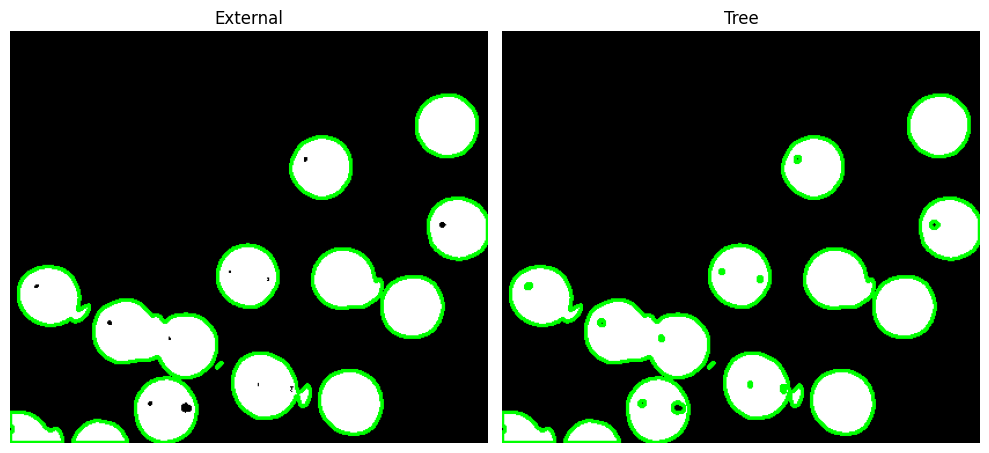

In [45]:
# Find contours
contours_ext, _ = cv2.findContours(
    thresh,
    cv2.RETR_EXTERNAL,
    cv2.CHAIN_APPROX_SIMPLE
)

contours_tree, hierarchy = cv2.findContours(
    thresh,
    cv2.RETR_TREE,
    cv2.CHAIN_APPROX_SIMPLE
)

print("External:", len(contours_ext))
print("Tree:", len(contours_tree))

# Create copies
img_ext = cv2.cvtColor(thresh, cv2.COLOR_GRAY2BGR)
img_tree = cv2.cvtColor(thresh, cv2.COLOR_GRAY2BGR)

# Draw contours
cv2.drawContours(img_ext, contours_ext, -1, (0,255,0), 2)
cv2.drawContours(img_tree, contours_tree, -1, (0,255,0), 2)

images = [img_ext, img_tree]
titles = [
    f"External",
    f"Tree"
]

combine_images_diff_sizes(images, titles, (10,5))

 `CHAIN_APPROX_NONE`

```text
● ● ● ● ● ● ● ● ●
●               ●
●               ●
●               ●
● ● ● ● ● ● ● ● ●

Every contour pixel is stored.
```

 `CHAIN_APPROX_SIMPLE`

```text
●---------------●
|               |
|               |
|               |
●---------------●

Only key points (corners) are stored.
```

NONE   : 404
SIMPLE : 8


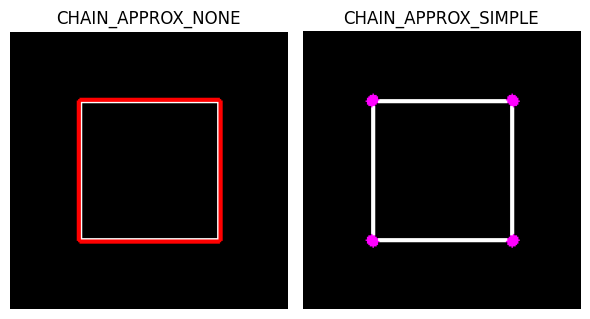

In [46]:
# Create rectangle
img = np.zeros((200, 200), dtype=np.uint8)
cv2.rectangle(img, (50, 50), (150, 150), 255, 2)

# Contours
cnt_none, _ = cv2.findContours(
    img.copy(),
    cv2.RETR_EXTERNAL,
    cv2.CHAIN_APPROX_NONE
)

cnt_simple, _ = cv2.findContours(
    img.copy(),
    cv2.RETR_EXTERNAL,
    cv2.CHAIN_APPROX_SIMPLE
)

print("NONE   :", len(cnt_none[0]))
print("SIMPLE :", len(cnt_simple[0]))

# Draw points
none_img = cv2.cvtColor(img, cv2.COLOR_GRAY2BGR)
simple_img = cv2.cvtColor(img, cv2.COLOR_GRAY2BGR)

for p in cnt_none[0]:
    x, y = p[0]
    cv2.circle(none_img, (x, y), 1, (0, 0, 255), -1)

for p in cnt_simple[0]:
    x, y = p[0]
    cv2.circle(simple_img, (x, y), 4, (255, 0, 255), -1)

images = [none_img, simple_img]
titles = [
    f"CHAIN_APPROX_NONE",
    f"CHAIN_APPROX_SIMPLE"
]

combine_images_diff_sizes(images, titles, (6,5))

# **Moments, Sorting, Approximating & Matching Contours**

1. Sort Contours by Area
2. Sort by Left to Right (Great for OCR)
3. Approximate Contours
4. Convex Hull



`moments()`         ---------> `center of object`

`sorted(...area)`   -> `largest first`

`sorted(...x)`      -----> `left-to-right (OCR)`

`approxPolyDP(`)    ---> `simplify shape`

`convexHull()`      -----> `remove `

Contours: 7


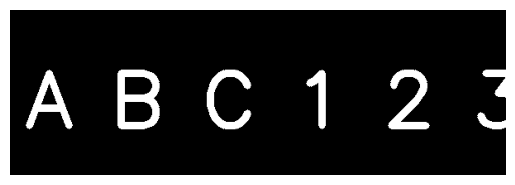

In [47]:
# Load an image using 'imread' specifying the path to image
gray = np.zeros((200, 600), dtype=np.uint8)

cv2.putText(gray, "A B C 1 2 3",
            (20, 140),
            cv2.FONT_HERSHEY_SIMPLEX,
            3, 255, 8)

plt.imshow(gray, cmap='gray')
plt.axis('off')
plt.show

# Find contours
contours, _ = cv2.findContours(
    gray,
    cv2.RETR_EXTERNAL,
    cv2.CHAIN_APPROX_SIMPLE
)

# # Remove tiny noise
# contours = [c for c in contours
#             if cv2.contourArea(c) > 100]

print("Contours:", len(contours))

Sort by Area      -> Compare B, A, C, 3, 2, 1

Left-to-Right     -> A → B → C → 1 → 2 → 3

Approximation     -> A and 3 simplify nicely

Convex Hull       -> B and A show holes/concavity effects

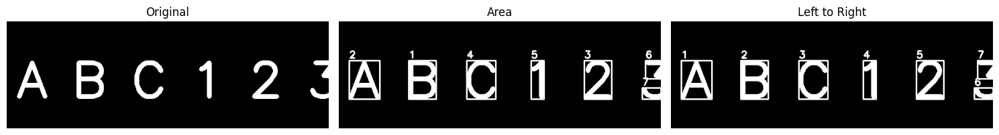

In [48]:
def put_and_draw(img, sorted):
    for i, c in enumerate(sorted[:]):
        x,y,w,h = cv2.boundingRect(c)

        cv2.rectangle(
            img,
            (x,y),
            (x+w,y+h),
            (255,255,255),
            2
        )

        cv2.putText(
            img,
            str(i+1),
            (x,y-5),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.6,
            (255,255,255),
            2
        )
    return img


img_area = gray.copy()

# Sort by area
area_sorted = sorted(contours, key=cv2.contourArea, reverse=True)

# put text and draw contour
img_area = put_and_draw(img_area, area_sorted)


# Sort Left → Right (OCR)
left_to_right = sorted(contours, key=lambda c: cv2.boundingRect(c)[0])

img_lr = gray.copy()

img_lr = put_and_draw(img_lr, left_to_right)


images = [gray, img_area, img_lr]
titles = [
    f"Original",
    f"Area",
    f"Left to Right"
]

combine_images_diff_sizes(images, titles, (15,5))

**`ApproxPolyDP`** and **`ConvexHull`**

ApproxPolyDP
= Simplify contour

ConvexHull
= Put a rubber band around it

Original: 8
Approx: 4


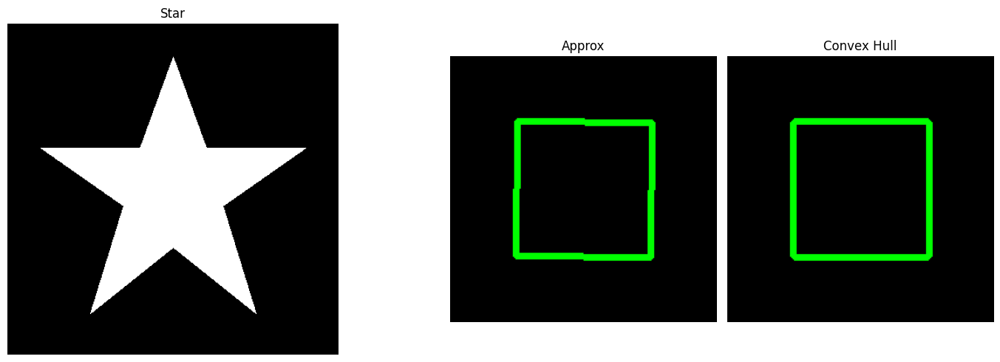

In [49]:
star = np.zeros((400,400), dtype=np.uint8)

pts = np.array([
    [200, 40],
    [240,150],
    [360,150],
    [260,220],
    [300,350],
    [200,270],
    [100,350],
    [140,220],
    [40,150],
    [160,150]
])

cv2.fillPoly(star, [pts], 255)

contours, _ = cv2.findContours(img, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

cnt = contours[0]


# approxPolyDP
peri = cv2.arcLength(cnt, True)

approx = cv2.approxPolyDP(cnt, 0.02 * peri, True)

print("Original:", len(cnt))
print("Approx:",  len(approx))

# ConvexHull
hull = cv2.convexHull(cnt)


# Draw
vis_star = cv2.cvtColor(img, cv2.COLOR_GRAY2BGR)
vis_star_hull = cv2.cvtColor(img, cv2.COLOR_GRAY2BGR)

cv2.drawContours(vis_star, [approx], -1, (0,255,0), 3)
cv2.drawContours(vis_star_hull, [hull], -1, (0,255,0), 4)

images = [star, vis_star, vis_star_hull]
titles = [
    f"Star",
    f"Approx",
    f"Convex Hull"
]

combine_images_diff_sizes(images, titles, (15, 5))



# **Matching Contours**
#### **cv2.matchShapes(contour template, contour, method, method parameter)**



Create an image with several real contours:

   ★       ○      □      ★

array([[0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       ...,
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0]], dtype=uint8)
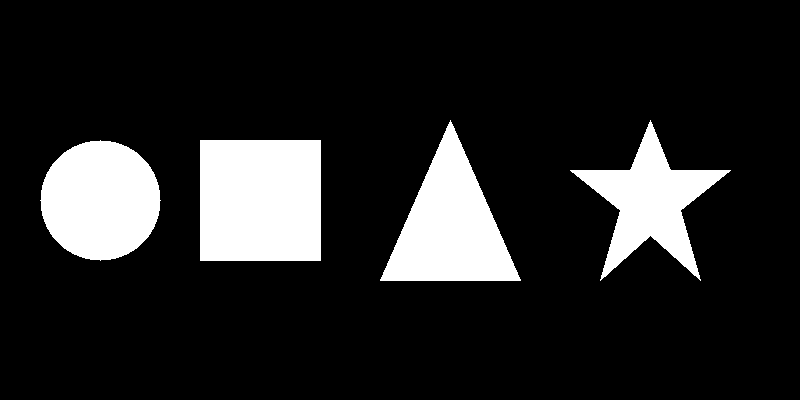

In [50]:

# Create an image with several real contours:

img = np.zeros((400, 800), dtype=np.uint8)

# Circle
cv2.circle(img, (100, 200), 60, 255, -1)

# Rectangle
cv2.rectangle(img, (200, 140), (320, 260), 255, -1)

# Triangle
triangle = np.array([
    [450, 120],
    [380, 280],
    [520, 280]
])
cv2.drawContours(img, [triangle], -1, 255, -1)

# Star
star = np.array([
    [650,120],
    [670,170],
    [730,170],
    [680,210],
    [700,280],
    [650,235],
    [600,280],
    [620,210],
    [570,170],
    [630,170]
])
cv2.drawContours(img, [star], -1, 255, -1)



Use **`Star`** as Template

Contours: 4


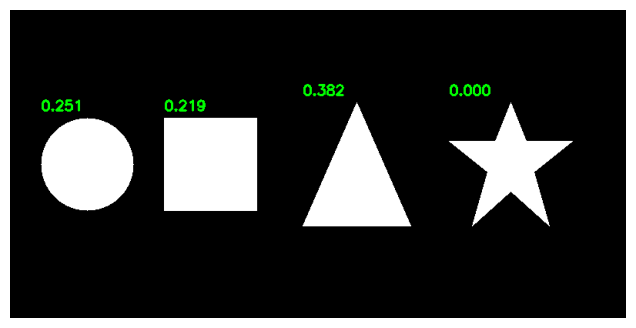

In [51]:
contours, _ = cv2.findContours(
    img,
    cv2.RETR_EXTERNAL,
    cv2.CHAIN_APPROX_SIMPLE
)

print("Contours:", len(contours))

contours = sorted(
    contours,
    key=lambda c: cv2.boundingRect(c)[0]
)

template = contours[-1]   # star


color = cv2.cvtColor(img, cv2.COLOR_GRAY2BGR)

for c in contours:

    score = cv2.matchShapes(
        template,
        c,
        cv2.CONTOURS_MATCH_I1,
        0
    )

    x,y,w,h = cv2.boundingRect(c)

    cv2.putText(
        color,
        f"{score:.3f}",
        (x,y-10),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.6,
        (0,255,0),
        2
    )

plt.figure(figsize=(10,4))
plt.imshow(cv2.cvtColor(color, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()

### Moments

```python
M = cv2.moments(contour)

cx = int(M["m10"]/M["m00"])
cy = int(M["m01"]/M["m00"])
```

### Common Moments

```text
m00 = Area

m10/m00 = Centroid X

m01/m00 = Centroid Y
```

### Uses

- Find contour center
- Compute area
- Shape analysis
- Object tracking

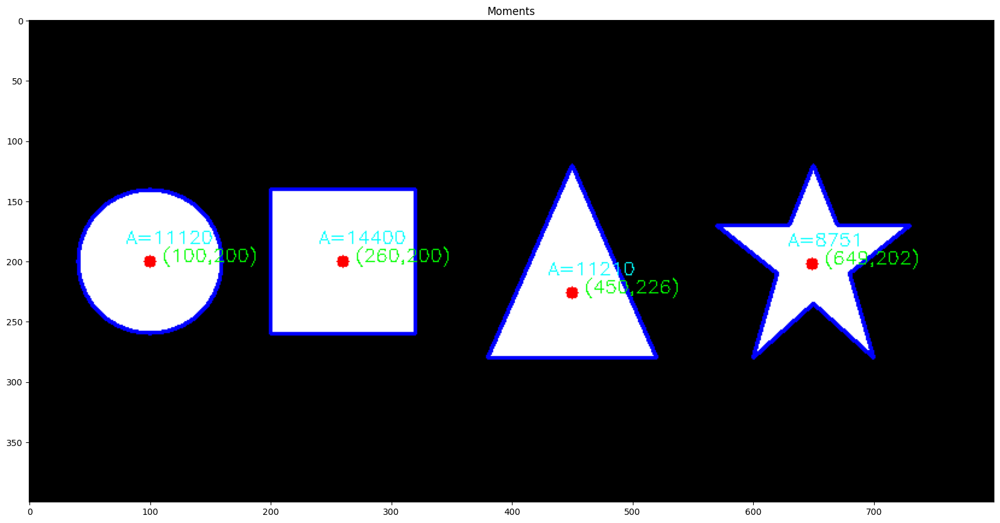

In [52]:
color = cv2.cvtColor(img, cv2.COLOR_GRAY2BGR)

for c in contours:

    M = cv2.moments(c)

    area = int(M["m00"])

    cx = int(M["m10"] / M["m00"])
    cy = int(M["m01"] / M["m00"])

    cv2.drawContours(color, [c], -1, (255, 0, 0), 2)

    cv2.circle(color, (cx, cy), 5, (0, 0, 255), -1)

    cv2.putText(
        color,
        f"({cx},{cy})",
        (cx + 10, cy),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.5,
        (0, 255, 0),
        1
    )

    cv2.putText(
        color,
        f"A={area}",
        (cx - 20, cy - 15),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.5,
        (255, 255, 0),
        1
    )
imshow('Moments', color)


# **Line, Circle and Blob Detection**

1. Houghlines
2. Probabilistic Houghlines
3. Hough Circles
4. Blob Detection


**`Quick Summary`**

HoughLines
`Detect infinite lines`

HoughLinesP
`Detect line segments`

HoughCircles
`Detect circles`

Blob Detection
`Detect round/connected regions`

## 1. **`Hough Lines`**

## 2. **`Probabilistic Hough Lines`**

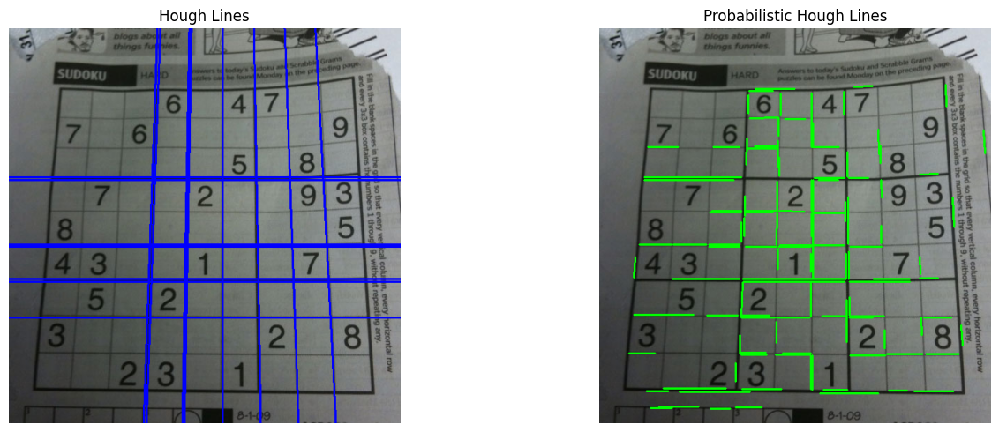

In [55]:
img = cv2.imread("sudoku.png")
houg_img = img.copy()
prob_img = img.copy()

# Canny Edges extracted
edges = autoCanny(img)

# 1. Probabilistic Hough Lines
# Run HoughLines using a rho accuracy of 1 pixel
# theta accuracy of np.pi / 180 which is 1 degree
# Our line threshold is set to 240 (number of points on line)
lines = cv2.HoughLines(edges, 1, np.pi / 180, 240)


for line in lines:
    rho, theta = line[0]

# We iterate through each line and convert it to the format
# required by cv2.lines (i.e. requiring end points)
for line in lines:
    rho, theta = line[0]
    a = np.cos(theta)
    b = np.sin(theta)
    x0 = a * rho
    y0 = b * rho
    x1 = int(x0 + 1000 * (-b))
    y1 = int(y0 + 1000 * (a))
    x2 = int(x0 - 1000 * (-b))
    y2 = int(y0 - 1000 * (a))
    cv2.line(houg_img, (x1, y1), (x2, y2), (255, 0, 0), 2)

# 2. Probabilistic Hough Lines
# Again we use the same rho and theta accuracies
# However, we specific a minimum vote (pts along line) of 100
# and Min line length of 3 pixels and max gap between lines of 25 pixels
lines = cv2.HoughLinesP(edges, 1, np.pi / 180, 100, 3, 25)

for line in lines:
    x1, y1, x2, y2 = line[0]
    cv2.line(prob_img,(x1,y1),(x2,y2),(0,255,0),2)

images = [houg_img, prob_img]
titles = [
    f"Hough Lines",
    f"Probabilistic Hough Lines"
]

combine_images_diff_sizes(images, titles, (15,5))

##3. **`Hough Circles`**



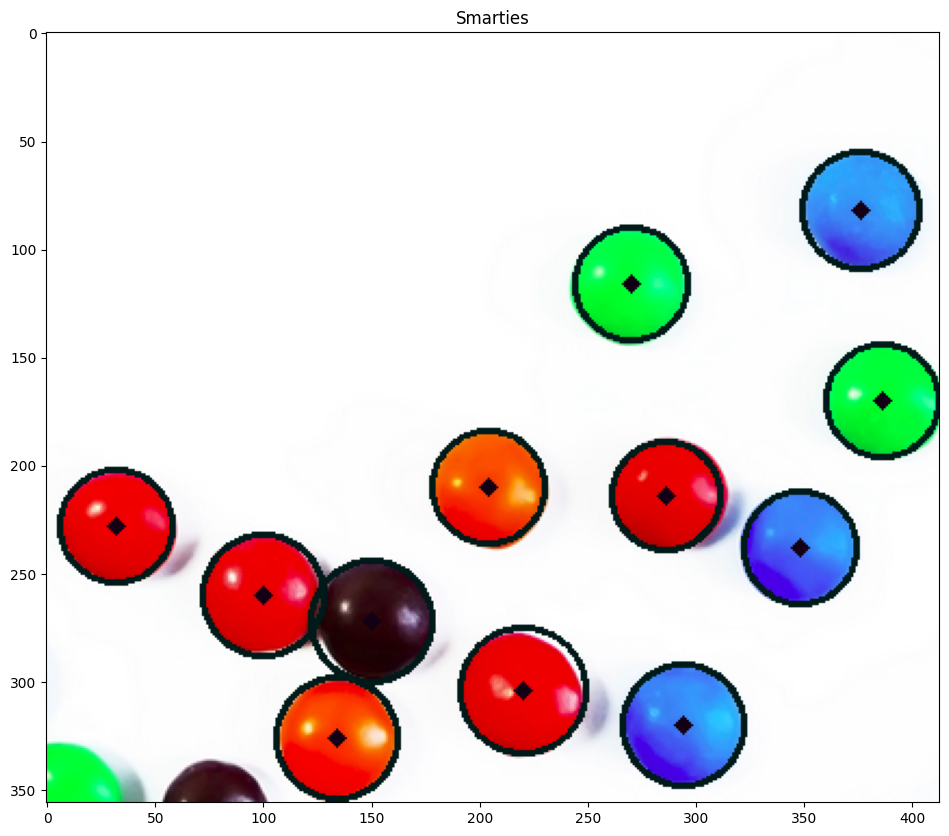

In [56]:
img = cv2.imread("smarties.png")
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

circles = cv2.HoughCircles(
    gray,
    cv2.HOUGH_GRADIENT,
    1,
    30,
    param1=50,
    param2=30,
    minRadius=10,
    maxRadius=50
)

circles = np.uint16(np.around(circles))

for c in circles[0]:
    x,y,r = c

    cv2.circle(img,(x,y),r,(25,25,0),2)
    cv2.circle(img,(x,y),2,(20,0,20),3)
imshow('Smarties', img)

## **Blob Detection**
The function `cv2.drawKeypoints`

![](https://opencv.org/wp-content/uploads/2025/05/BlobTest.jpg)

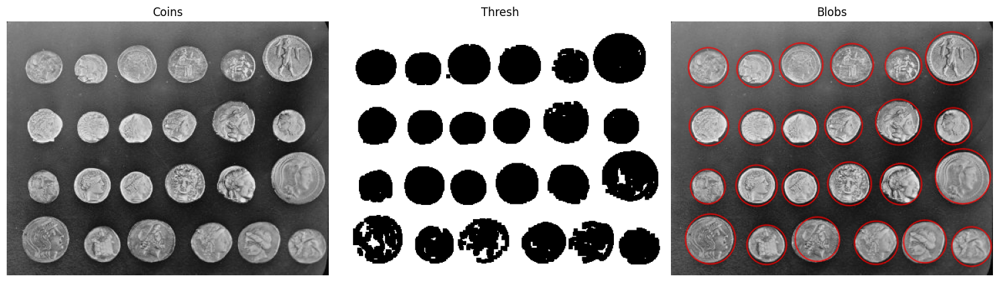

In [57]:
from skimage import data
image = data.coins()
coins= image.copy()

_, img_th = cv2.threshold(coins, 150, 255, cv2.THRESH_BINARY_INV)

# Closing - Good for removing noise
thresh = cv2.erode(img_th, kernel)

# Setup SimpleBlobDetector parameters
params = cv2.SimpleBlobDetector_Params()

# Thresholds for binarization
params.minThreshold = 10
params.maxThreshold = 200

# Filter by Area
params.filterByArea = True
params.minArea = 150

# Filter by Circularity
params.filterByCircularity = True
params.minCircularity = 0.2

# Filter by Convexity
params.filterByConvexity = True
params.minConvexity = 0.87

# Filter by Inertia
params.filterByInertia = True
params.minInertiaRatio = 0.7

detector = cv2.SimpleBlobDetector_create(params)

keypoints = detector.detect(thresh)

blobs = cv2.drawKeypoints(
    coins,
    keypoints,
    None,
    (0,0,255),
    cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS
)

images = [coins,thresh , blobs]
titles = [
    f"Coins",
    f"Thresh",
    f"Blobs"
]

combine_images_diff_sizes(images, titles, (15,5))




# **Finding Corners**

1. To use **`Harris Corners`** to find corners
2. Use **`Good Features to Track`**


**Harris Corner Detection**

Detect Corners

**Good Features To Track**

More practical than Harris.
* Finds Harris-like corners
* Ranks them by quality
* Removes nearby duplicates
* Returns the strongest


Harris
```text
  ★★★★★★★★★★★★★
  Many detections
```
Good Features
```text
  ★     ★
      ★
  ★     ★
```
Best detections only


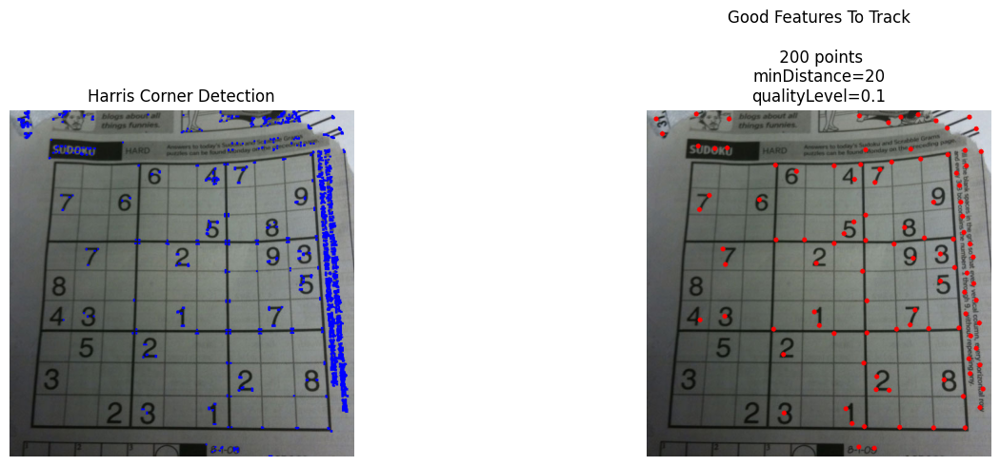

In [58]:

# img = data.page()
img = cv2.imread("sudoku.png")
harris = img.copy()
goodFeatures = img.copy()

gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)



# Harris Corner Detection
corners = cv2.cornerHarris(
    gray,
    blockSize=2,
    ksize=3,
    k=0.04
)

corners = cv2.dilate(corners, None)

harris[corners > 0.01 * corners.max()] = [255, 0, 0]




# goodFeaturesToTrack
corners = cv2.goodFeaturesToTrack(
    gray,
    maxCorners=200,
    qualityLevel=0.1,
    minDistance=20
)

corners = np.int32(corners)

# goodFeatures = cv2.cvtColor(img, cv2.COLOR_GRAY2BGR)

for corner in corners:
    x, y = corner.ravel()
    cv2.circle(goodFeatures, (x,y), 4, (0,0,255), -1)


images = [harris, goodFeatures]
titles = [
    f"Harris Corner Detection",
    f"Good Features To Track\n\n 200 points\nminDistance=20\nqualityLevel=0.1"
]

combine_images_diff_sizes(images, titles, (15,5))

## **Simple Face Detection using Haarcascade Classifiers**

In [59]:
!wget -O group.jpg \
https://upload.wikimedia.org/wikipedia/commons/3/37/Dagestani_man_and_woman.jpg

import urllib.request

urllib.request.urlretrieve(
    "https://raw.githubusercontent.com/opencv/opencv/master/data/haarcascades/haarcascade_frontalface_default.xml",
    "haarcascade_frontalface_default.xml"
)

urllib.request.urlretrieve(
    "https://raw.githubusercontent.com/opencv/opencv/master/data/haarcascades/haarcascade_eye.xml",
    "haarcascade_eye.xml"
)

--2026-10-17 11:14:26--  https://upload.wikimedia.org/wikipedia/commons/3/37/Dagestani_man_and_woman.jpg
Resolving upload.wikimedia.org (upload.wikimedia.org)... 208.80.154.240, 2620:0:861:ed1a::2:b
Connecting to upload.wikimedia.org (upload.wikimedia.org)|208.80.154.240|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 1588507 (1.5M) [image/jpeg]
Saving to: ‘group.jpg’

group.jpg           100%[===================>]   1.51M  --.-KB/s    in 0.05s   

2026-10-17 11:14:26 (30.0 MB/s) - ‘group.jpg’ saved [1588507/1588507]



In [ ]:
# !pip uninstall -y opencv-python opencv-contrib-python opencv-python-headless
# !pip install opencv-contrib-python==4.10.0.84

Faces found: 3


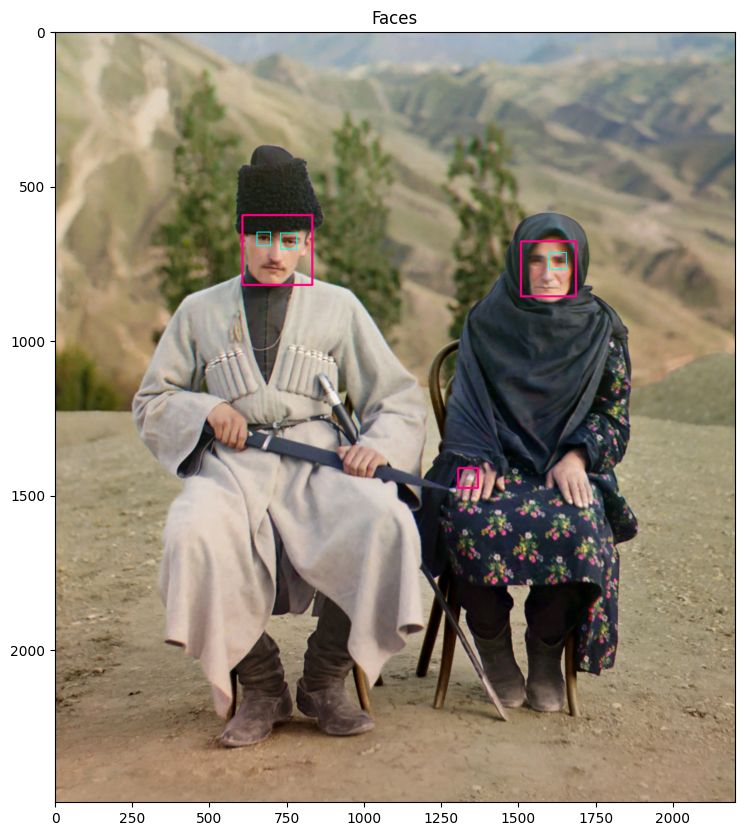

In [80]:
img = cv2.imread("group.jpg")
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)


face_classifier = cv2.CascadeClassifier("haarcascade_frontalface_default.xml")

eye_classifier = cv2.CascadeClassifier("haarcascade_eye.xml")

# Our classifier returns the ROI of the detected face as a tuple
# It stores the top left coordinate and the bottom right coordiantes
faces = face_classifier.detectMultiScale(gray, scaleFactor = 1.2, minNeighbors = 5)

print("Faces found:", len(faces))

for (x,y,w,h) in faces:
    cv2.rectangle(img,(x,y),(x+w,y+h),(127,0,255),5)
    roi_gray = gray[y:y+h, x:x+w]
    roi_color = img[y:y+h, x:x+w]
    eyes = eye_classifier.detectMultiScale(roi_gray, 1.1, 3)
    for (ex,ey,ew,eh) in eyes:
        cv2.rectangle(roi_color,(ex,ey),(ex+ew,ey+eh),(255,255,0),2)

imshow("Faces", img)